In [1]:
from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix, classification_report
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

warnings.filterwarnings("ignore", category=FutureWarning)

# Use the notebook's current folder as the project root.
ROOT = Path.cwd()
MODEL_DIR = ROOT / "model"
OUTPUT_DIR = ROOT / "outputs"

# Keep results from the two experiments in separate folders.
ORIGINAL_MODEL_DIR = MODEL_DIR / "original"
BALANCED_MODEL_DIR = MODEL_DIR / "oversampled"
ORIGINAL_OUTPUT_DIR = OUTPUT_DIR / "original"
BALANCED_OUTPUT_DIR = OUTPUT_DIR / "oversampled"

for folder in [MODEL_DIR, OUTPUT_DIR, ORIGINAL_MODEL_DIR, BALANCED_MODEL_DIR,
               ORIGINAL_OUTPUT_DIR, BALANCED_OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
SAMPLE_SIZE = 12000  # A stratified subset keeps model training practical.
TARGET_NAME = "income"
POSITIVE_LABEL = ">50K"

print("Project directory:", ROOT)
print("Random state:", RANDOM_STATE)
print("Experiment sample size:", SAMPLE_SIZE)

Project directory: /Users/janhavi/anaconda_projects/db/Ml assignment/ML assgn 2
Random state: 42
Experiment sample size: 12000


In [2]:
def load_adult_dataset():
    """Download the public UCI Adult dataset and clean basic labels."""
    print("Loading the UCI Adult Income dataset...")
    adult = fetch_ucirepo(id=2)

    X = adult.data.features.copy()
    y_frame = adult.data.targets.copy()
    y = y_frame.iloc[:, 0] if isinstance(y_frame, pd.DataFrame) else pd.Series(y_frame)

    # Standardize column names and remove the period used in some target labels.
    X.columns = [str(column).strip().replace("-", "_") for column in X.columns]
    y = y.astype(str).str.strip().str.replace(".", "", regex=False)

    # In this dataset, '?' represents an unknown/missing feature value.
    X = X.replace(r"^\s*\?\s*$", np.nan, regex=True)
    y.name = TARGET_NAME
    return X, y

X, y = load_adult_dataset()

print("Dataset loaded successfully!")
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Loading the UCI Adult Income dataset...
Dataset loaded successfully!
Feature shape: (48842, 14)
Target shape: (48842,)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


In [3]:
def prepare_data(X, y):
    """Inspect the dataset, remove complete duplicates, sample and split it."""
    print("\n--- Dataset checks ---")
    print("Rows before duplicate removal:", len(X))

    # Include the target when checking duplicates so records with different labels
    # are not mistakenly treated as identical complete observations.
    combined = X.copy()
    combined[TARGET_NAME] = y.values
    duplicate_count = combined.duplicated().sum()
    print("Duplicate complete records:", duplicate_count)

    combined = combined.drop_duplicates()
    X_clean = combined.drop(columns=[TARGET_NAME])
    y_clean = combined[TARGET_NAME]
    print("Rows after duplicate removal:", len(X_clean))

    # Report missing values before imputation.
    print("\nMissing values by feature:")
    print(X_clean.isna().sum().sort_values(ascending=False).to_string())

    # Report the class imbalance in the cleaned dataset.
    print("\nClass counts:")
    print(y_clean.value_counts().to_string())
    print("\nClass proportions:")
    print((y_clean.value_counts(normalize=True) * 100).round(2).astype(str).add("%").to_string())

    # Use stratified sampling to preserve class proportions in the 12,000-row sample.
    if SAMPLE_SIZE and len(X_clean) > SAMPLE_SIZE:
        X_clean, _, y_clean, _ = train_test_split(
            X_clean, y_clean,
            train_size=SAMPLE_SIZE,
            random_state=RANDOM_STATE,
            stratify=y_clean
        )

    # Use the same reproducible 80:20 stratified split for both experiments.
    X_train, X_test, y_train, y_test = train_test_split(
        X_clean, y_clean,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y_clean
    )

    # Export held-out test examples with their actual labels.
    test_export = X_test.copy()
    test_export[TARGET_NAME] = y_test.values
    test_export.to_csv(ROOT / "test_data.csv", index=False)

    print(f"\nExperiment sample size: {len(X_clean)}")
    print(f"Training rows: {len(X_train)} ({len(X_train) / len(X_clean):.0%})")
    print(f"Testing rows: {len(X_test)} ({len(X_test) / len(X_clean):.0%})")
    print(f"Training positive-class share: {(y_train == POSITIVE_LABEL).mean():.3f}")
    print(f"Testing positive-class share: {(y_test == POSITIVE_LABEL).mean():.3f}")

    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = prepare_data(X, y)
print("\nData preparation completed.")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Test data saved to:", ROOT / "test_data.csv")


--- Dataset checks ---
Rows before duplicate removal: 48842
Duplicate complete records: 52
Rows after duplicate removal: 48790

Missing values by feature:
occupation        2805
workclass         2795
native_country     856
age                  0
fnlwgt               0
education            0
education_num        0
marital_status       0
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0

Class counts:
income
<=50K    37109
>50K     11681

Class proportions:
income
<=50K    76.06%
>50K     23.94%

Experiment sample size: 12000
Training rows: 9600 (80%)
Testing rows: 2400 (20%)
Training positive-class share: 0.239
Testing positive-class share: 0.240

Data preparation completed.
Training shape: (9600, 14)
Testing shape: (2400, 14)
Test data saved to: /Users/janhavi/anaconda_projects/db/Ml assignment/ML assgn 2/test_data.csv


In [4]:
def build_preprocessor(X_train):
    """Create numeric and categorical transformations; do not fit them here."""
    numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
    categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    return preprocessor, numeric_features, categorical_features

preprocessor, numeric_features, categorical_features = build_preprocessor(X_train)
print("Preprocessor created successfully.")
print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Preprocessor created successfully.
Numerical features: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical features: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


In [5]:
def get_classifiers(use_class_weight=False):
    """Return the five required classifiers with reproducible settings."""
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1500, solver="liblinear", random_state=RANDOM_STATE
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=12, min_samples_leaf=5, random_state=RANDOM_STATE
        ),
        "kNN": KNeighborsClassifier(
            n_neighbors=7, weights="distance", n_jobs=-1
        ),
        "Naive Bayes": GaussianNB(),
        "Random Forest": RandomForestClassifier(
            n_estimators=250,
            min_samples_leaf=2,
            class_weight="balanced_subsample" if use_class_weight else None,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    }


def build_models_original(preprocessor):
    """Build standard scikit-learn pipelines without oversampling."""
    classifiers = get_classifiers(use_class_weight=True)
    return {
        name: Pipeline(steps=[
            ("preprocessing", clone(preprocessor)),
            ("classifier", estimator)
        ])
        for name, estimator in classifiers.items()
    }


def build_models_balanced(preprocessor):
    """Build imbalanced-learn pipelines with training-only random oversampling."""
    classifiers = get_classifiers(use_class_weight=False)
    return {
        name: ImbPipeline(steps=[
            ("preprocessing", clone(preprocessor)),
            ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
            ("classifier", estimator)
        ])
        for name, estimator in classifiers.items()
    }

pipelines_original = build_models_original(preprocessor)
pipelines_balanced = build_models_balanced(preprocessor)

print("Original pipelines:", list(pipelines_original.keys()))
print("Oversampled pipelines:", list(pipelines_balanced.keys()))

Original pipelines: ['Logistic Regression', 'Decision Tree', 'kNN', 'Naive Bayes', 'Random Forest']
Oversampled pipelines: ['Logistic Regression', 'Decision Tree', 'kNN', 'Naive Bayes', 'Random Forest']


In [6]:
print("Training class distribution before oversampling:")
print(y_train.value_counts())

# Demonstrate the expected class counts after random oversampling.
# These sampled rows are not used directly to train the models; the sampler
# inside each balanced pipeline performs this operation during model fitting.
sampler_check = RandomOverSampler(random_state=RANDOM_STATE)
_, y_train_resampled_check = sampler_check.fit_resample(X_train, y_train)

print("\nTraining class distribution after oversampling (demonstration):")
print(y_train_resampled_check.value_counts())

print("\nTest class distribution (unchanged):")
print(y_test.value_counts())

Training class distribution before oversampling:
income
<=50K    7302
>50K     2298
Name: count, dtype: int64

Training class distribution after oversampling (demonstration):
income
<=50K    7302
>50K     7302
Name: count, dtype: int64

Test class distribution (unchanged):
income
<=50K    1825
>50K      575
Name: count, dtype: int64


In [7]:
def evaluate_models(models, X_train, X_test, y_train, y_test,
                    model_output_dir, result_output_dir, experiment_name):
    """Fit models and calculate six metrics, keeping experiment files separate."""
    rows = []
    fitted_models = {}
    model_output_dir.mkdir(parents=True, exist_ok=True)
    result_output_dir.mkdir(parents=True, exist_ok=True)

    for name, pipeline in models.items():
        print(f"\nTraining {name} ({experiment_name})...")

        # Fitting the pipeline learns preprocessing only from training data.
        # For ImbPipeline, the sampler is applied only during this fit operation.
        pipeline.fit(X_train, y_train)
        fitted_models[name] = pipeline

        # Evaluate on the original, untouched test set.
        predictions = pipeline.predict(X_test)
        probabilities = pipeline.predict_proba(X_test)
        classifier = pipeline.named_steps["classifier"]
        classes = list(classifier.classes_)
        positive_column = classes.index(POSITIVE_LABEL)
        positive_probabilities = probabilities[:, positive_column]
        y_test_binary = (y_test == POSITIVE_LABEL).astype(int)

        metrics = {
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "AUC": roc_auc_score(y_test_binary, positive_probabilities),
            "Precision": precision_score(
                y_test, predictions, pos_label=POSITIVE_LABEL, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, pos_label=POSITIVE_LABEL, zero_division=0
            ),
            "F1": f1_score(
                y_test, predictions, pos_label=POSITIVE_LABEL, zero_division=0
            ),
            "MCC": matthews_corrcoef(y_test, predictions)
        }
        rows.append(metrics)

        # Save each trained model in its own experiment folder.
        safe_name = name.lower().replace(" ", "_")
        joblib.dump(pipeline, model_output_dir / f"{safe_name}.joblib")

        print(pd.Series(metrics).to_string())
        print("\nClassification report:")
        print(classification_report(y_test, predictions, zero_division=0))

        # Save a confusion matrix for this model.
        cm = confusion_matrix(y_test, predictions, labels=["<=50K", ">50K"])
        plt.figure(figsize=(5, 4))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["<=50K", ">50K"],
            yticklabels=["<=50K", ">50K"]
        )
        plt.title(f"Confusion Matrix – {name} ({experiment_name})")
        plt.xlabel("Predicted label")
        plt.ylabel("True label")
        plt.tight_layout()
        plt.savefig(result_output_dir / f"confusion_matrix_{safe_name}.png",
                    dpi=160, bbox_inches="tight")
        plt.show()
        plt.close()

    results = pd.DataFrame(rows).set_index("Model")
    results.to_csv(result_output_dir / "model_metrics.csv")
    return results, fitted_models


Training Logistic Regression (Original – no oversampling)...
Model        Logistic Regression
Accuracy                0.855417
AUC                     0.909161
Precision               0.741525
Recall                  0.608696
F1                      0.668577
MCC                     0.581858

Classification report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      1825
        >50K       0.74      0.61      0.67       575

    accuracy                           0.86      2400
   macro avg       0.81      0.77      0.79      2400
weighted avg       0.85      0.86      0.85      2400



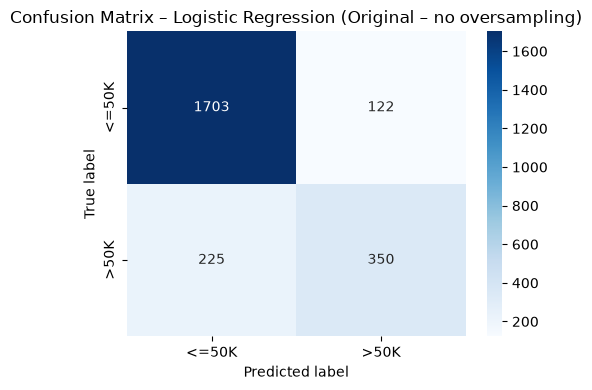


Training Decision Tree (Original – no oversampling)...
Model        Decision Tree
Accuracy             0.845
AUC                0.87351
Precision         0.710145
Recall            0.596522
F1                0.648393
MCC               0.553382

Classification report:
              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90      1825
        >50K       0.71      0.60      0.65       575

    accuracy                           0.84      2400
   macro avg       0.79      0.76      0.77      2400
weighted avg       0.84      0.84      0.84      2400



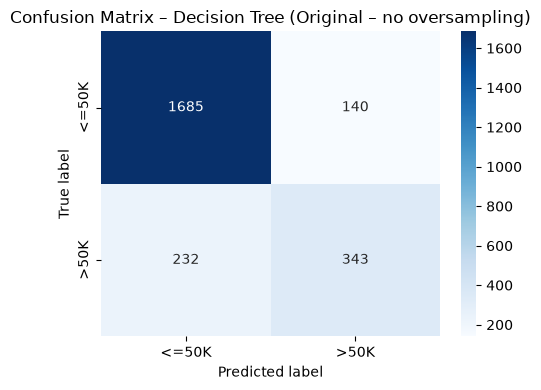


Training kNN (Original – no oversampling)...
Model             kNN
Accuracy      0.82875
AUC          0.873207
Precision    0.660784
Recall       0.586087
F1           0.621198
MCC          0.512613

Classification report:
              precision    recall  f1-score   support

       <=50K       0.87      0.91      0.89      1825
        >50K       0.66      0.59      0.62       575

    accuracy                           0.83      2400
   macro avg       0.77      0.75      0.76      2400
weighted avg       0.82      0.83      0.83      2400



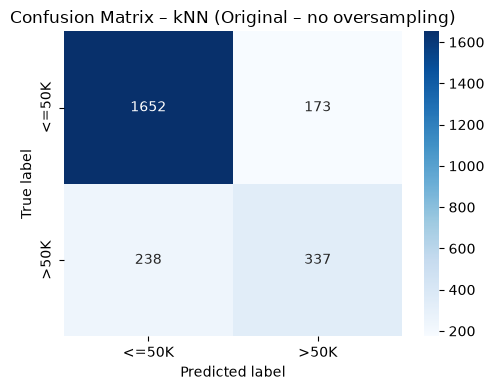


Training Naive Bayes (Original – no oversampling)...
Model        Naive Bayes
Accuracy        0.344167
AUC             0.619393
Precision       0.264276
Recall          0.973913
F1              0.415739
MCC             0.158862

Classification report:
              precision    recall  f1-score   support

       <=50K       0.95      0.15      0.25      1825
        >50K       0.26      0.97      0.42       575

    accuracy                           0.34      2400
   macro avg       0.61      0.56      0.33      2400
weighted avg       0.78      0.34      0.29      2400



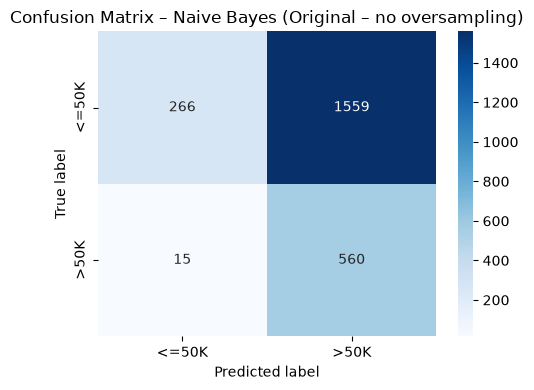


Training Random Forest (Original – no oversampling)...
Model        Random Forest
Accuracy          0.838333
AUC               0.915191
Precision         0.623841
Recall             0.81913
F1                0.708271
MCC               0.609901

Classification report:
              precision    recall  f1-score   support

       <=50K       0.94      0.84      0.89      1825
        >50K       0.62      0.82      0.71       575

    accuracy                           0.84      2400
   macro avg       0.78      0.83      0.80      2400
weighted avg       0.86      0.84      0.85      2400



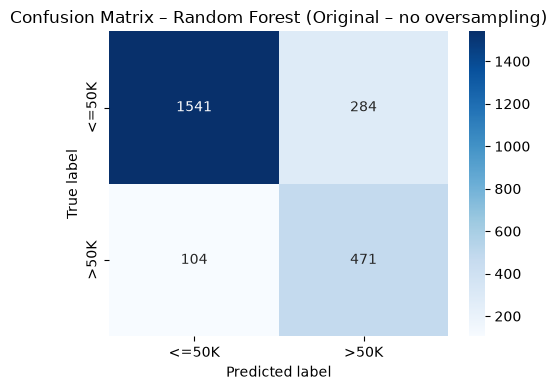


Original model comparison:


,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8554,0.9092,0.7415,0.6087,0.6686,0.5819
Decision Tree,0.8450,0.8735,0.7101,0.5965,0.6484,0.5534
kNN,0.8288,0.8732,0.6608,0.5861,0.6212,0.5126
Naive Bayes,0.3442,0.6194,0.2643,0.9739,0.4157,0.1589
Random Forest,0.8383,0.9152,0.6238,0.8191,0.7083,0.6099


In [8]:
results_original, fitted_models_original = evaluate_models(
    pipelines_original,
    X_train, X_test, y_train, y_test,
    ORIGINAL_MODEL_DIR, ORIGINAL_OUTPUT_DIR,
    experiment_name="Original – no oversampling"
)

print("\nOriginal model comparison:")
display(results_original.round(4))


Training Logistic Regression (Random Oversampling)...
Model        Logistic Regression
Accuracy                0.809167
AUC                     0.908188
Precision               0.568421
Recall                  0.845217
F1                       0.67972
MCC                     0.573121

Classification report:
              precision    recall  f1-score   support

       <=50K       0.94      0.80      0.86      1825
        >50K       0.57      0.85      0.68       575

    accuracy                           0.81      2400
   macro avg       0.76      0.82      0.77      2400
weighted avg       0.85      0.81      0.82      2400



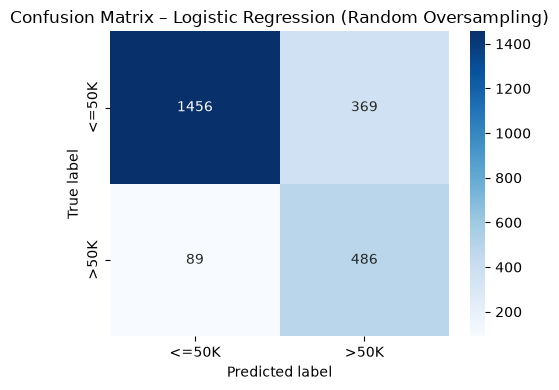


Training Decision Tree (Random Oversampling)...
Model        Decision Tree
Accuracy           0.80625
AUC               0.852795
Precision          0.56875
Recall            0.791304
F1                0.661818
MCC               0.545314

Classification report:
              precision    recall  f1-score   support

       <=50K       0.93      0.81      0.86      1825
        >50K       0.57      0.79      0.66       575

    accuracy                           0.81      2400
   macro avg       0.75      0.80      0.76      2400
weighted avg       0.84      0.81      0.82      2400



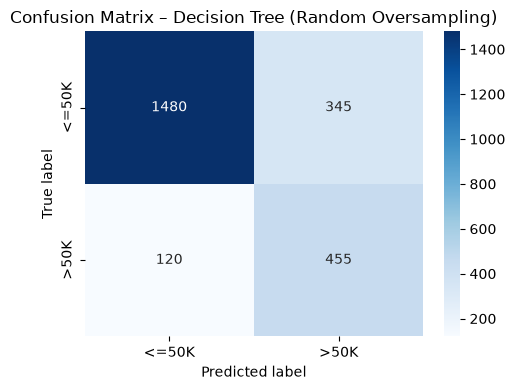


Training kNN (Random Oversampling)...
Model             kNN
Accuracy     0.782917
AUC          0.861236
Precision    0.531991
Recall        0.78087
F1            0.63284
MCC          0.504546

Classification report:
              precision    recall  f1-score   support

       <=50K       0.92      0.78      0.85      1825
        >50K       0.53      0.78      0.63       575

    accuracy                           0.78      2400
   macro avg       0.73      0.78      0.74      2400
weighted avg       0.83      0.78      0.79      2400



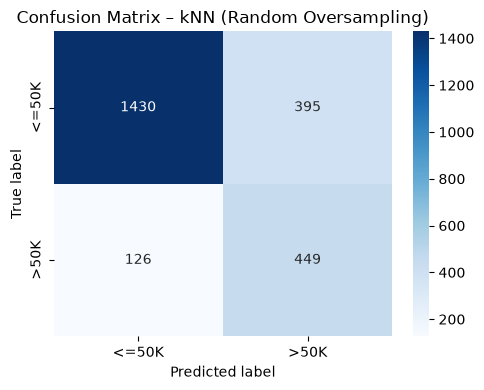


Training Naive Bayes (Random Oversampling)...
Model        Naive Bayes
Accuracy        0.353333
AUC             0.641888
Precision       0.267048
Recall          0.973913
F1              0.419162
MCC             0.169278

Classification report:
              precision    recall  f1-score   support

       <=50K       0.95      0.16      0.27      1825
        >50K       0.27      0.97      0.42       575

    accuracy                           0.35      2400
   macro avg       0.61      0.57      0.34      2400
weighted avg       0.79      0.35      0.31      2400



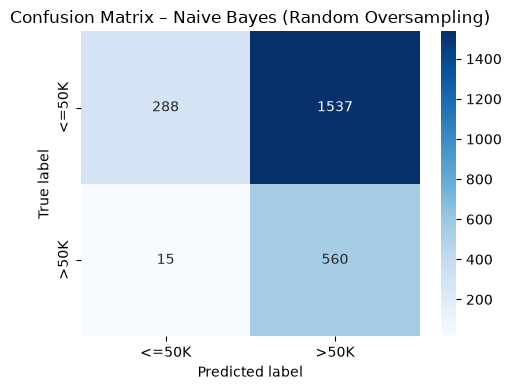


Training Random Forest (Random Oversampling)...
Model        Random Forest
Accuracy          0.840417
AUC               0.913256
Precision         0.633333
Recall            0.793043
F1                0.704247
MCC               0.603918

Classification report:
              precision    recall  f1-score   support

       <=50K       0.93      0.86      0.89      1825
        >50K       0.63      0.79      0.70       575

    accuracy                           0.84      2400
   macro avg       0.78      0.82      0.80      2400
weighted avg       0.86      0.84      0.85      2400



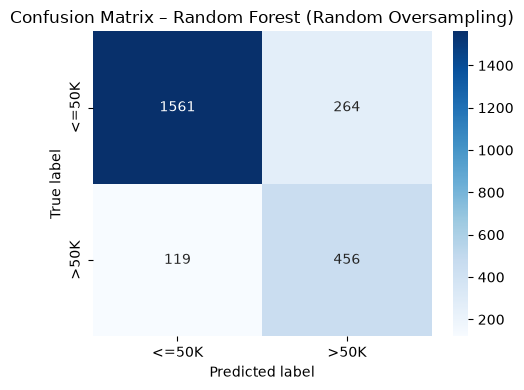


Oversampled model comparison:


,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8092,0.9082,0.5684,0.8452,0.6797,0.5731
Decision Tree,0.8062,0.8528,0.5688,0.7913,0.6618,0.5453
kNN,0.7829,0.8612,0.5320,0.7809,0.6328,0.5045
Naive Bayes,0.3533,0.6419,0.2670,0.9739,0.4192,0.1693
Random Forest,0.8404,0.9133,0.6333,0.7930,0.7042,0.6039


In [9]:
results_balanced, fitted_models_balanced = evaluate_models(
    pipelines_balanced,
    X_train, X_test, y_train, y_test,
    BALANCED_MODEL_DIR, BALANCED_OUTPUT_DIR,
    experiment_name="Random Oversampling"
)

print("\nOversampled model comparison:")
display(results_balanced.round(4))

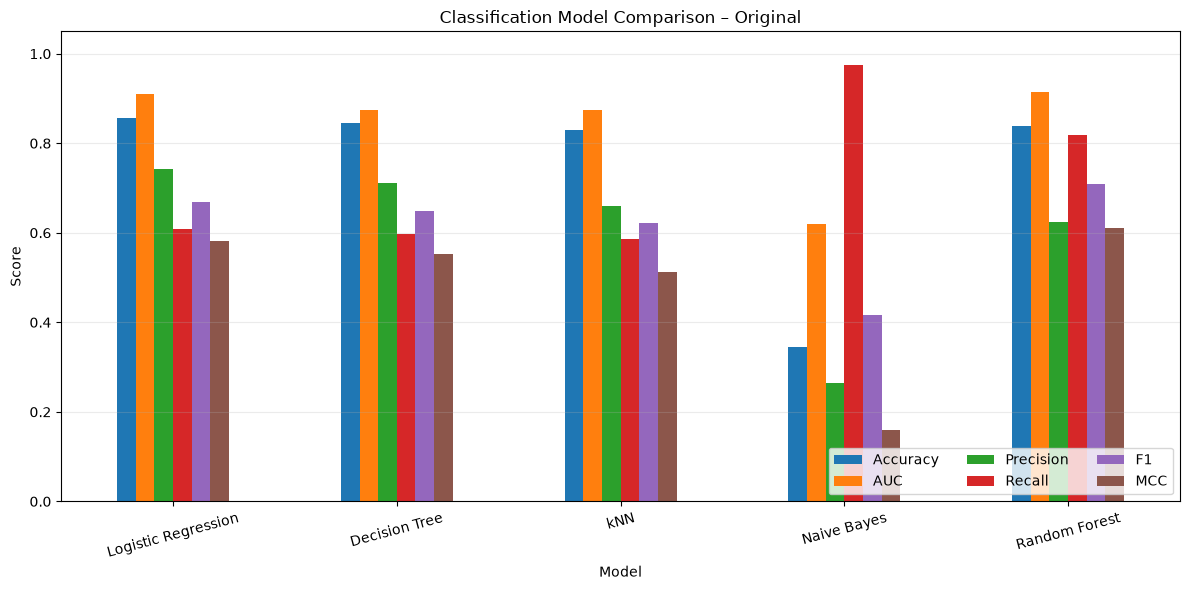

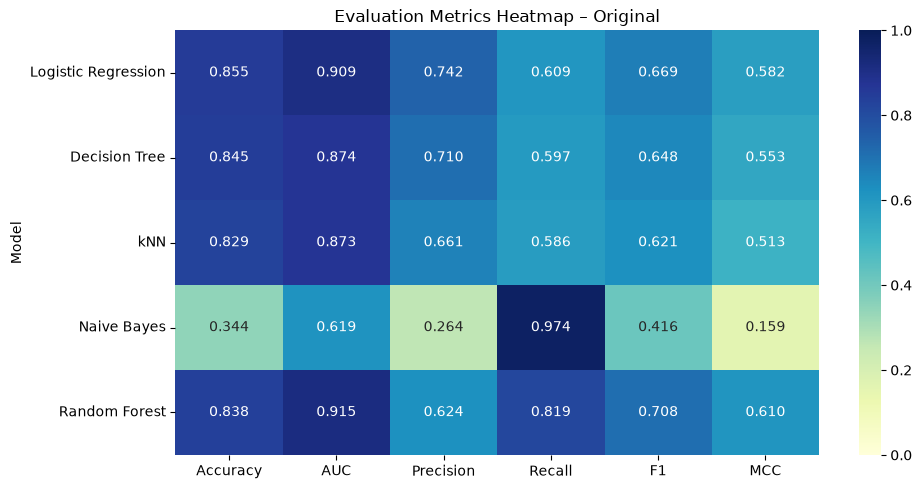

Visualizations saved in: /Users/janhavi/anaconda_projects/db/Ml assignment/ML assgn 2/outputs/original


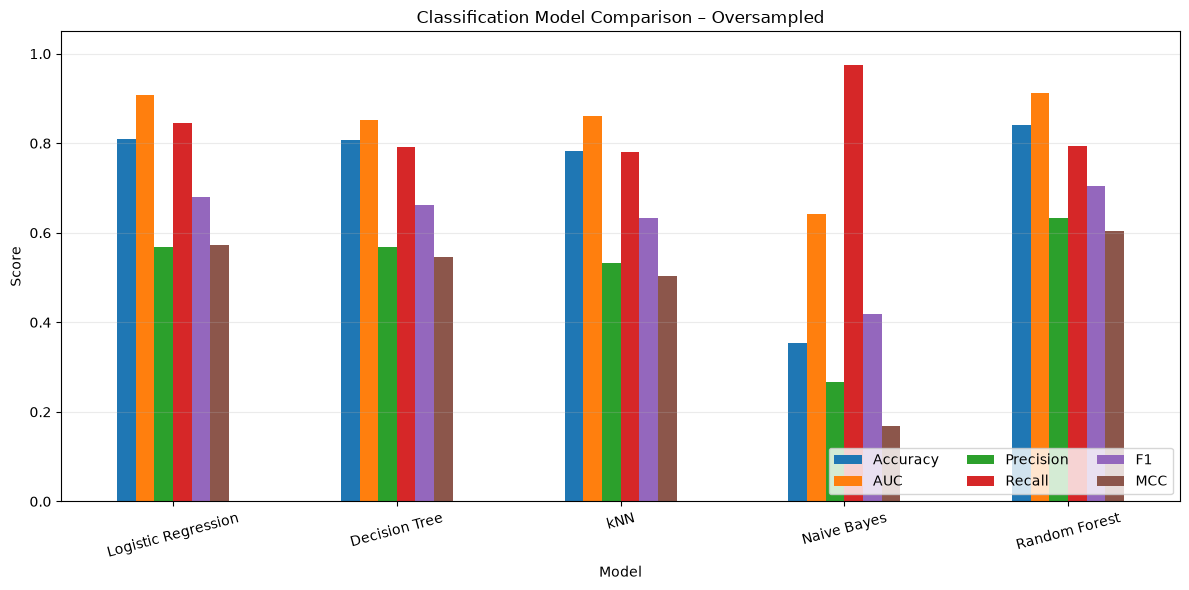

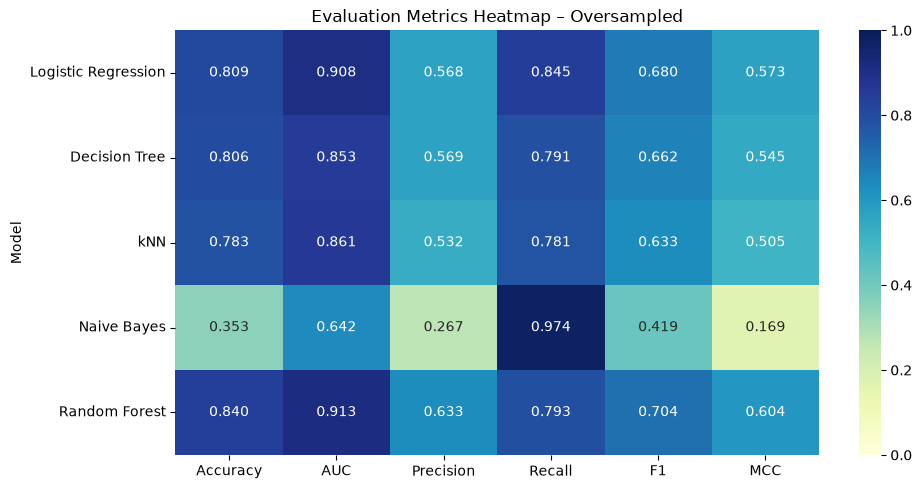

Visualizations saved in: /Users/janhavi/anaconda_projects/db/Ml assignment/ML assgn 2/outputs/oversampled


In [10]:
def create_visualizations(results, output_dir, experiment_name):
    """Display and save a grouped metric chart and a metric heatmap."""
    output_dir.mkdir(parents=True, exist_ok=True)
    safe_experiment_name = experiment_name.lower().replace(" ", "_").replace("–", "-")

    # Grouped bar chart compares all six metrics across the five classifiers.
    ax = results.plot(kind="bar", figsize=(12, 6), ylim=(0, 1.05), rot=15)
    ax.set_title(f"Classification Model Comparison – {experiment_name}")
    ax.set_ylabel("Score")
    ax.set_xlabel("Model")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(loc="lower right", ncol=3)
    plt.tight_layout()
    plt.savefig(output_dir / f"all_metrics_comparison_{safe_experiment_name}.png",
                dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

    # Heatmap makes it easier to compare strong and weak metric values.
    plt.figure(figsize=(10, 5))
    sns.heatmap(results, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1)
    plt.title(f"Evaluation Metrics Heatmap – {experiment_name}")
    plt.tight_layout()
    plt.savefig(output_dir / f"metrics_heatmap_{safe_experiment_name}.png",
                dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"Visualizations saved in: {output_dir}")

create_visualizations(results_original, ORIGINAL_OUTPUT_DIR, "Original")
create_visualizations(results_balanced, BALANCED_OUTPUT_DIR, "Oversampled")

In [11]:
comparison = pd.concat(
    {"Original": results_original, "Oversampled": results_balanced},
    axis=1
)

print("Original vs. oversampled model comparison:")
display(comparison.round(4))

# Save the combined comparison table for the report.
comparison.to_csv(OUTPUT_DIR / "original_vs_oversampled_comparison.csv")

# Compare F1 scores separately for a quick view of the precision/recall balance.
f1_comparison = pd.DataFrame({
    "Original F1": results_original["F1"],
    "Oversampled F1": results_balanced["F1"]
})
print("\nF1-score comparison:")
display(f1_comparison.round(4))

Original vs. oversampled model comparison:


Original                                            \
                    Accuracy     AUC Precision  Recall      F1     MCC   
Model                                                                    
Logistic Regression   0.8554  0.9092    0.7415  0.6087  0.6686  0.5819   
Decision Tree         0.8450  0.8735    0.7101  0.5965  0.6484  0.5534   
kNN                   0.8288  0.8732    0.6608  0.5861  0.6212  0.5126   
Naive Bayes           0.3442  0.6194    0.2643  0.9739  0.4157  0.1589   
Random Forest         0.8383  0.9152    0.6238  0.8191  0.7083  0.6099   

                    Oversampled                                            
                       Accuracy     AUC Precision  Recall      F1     MCC  
Model                                                                      
Logistic Regression      0.8092  0.9082    0.5684  0.8452  0.6797  0.5731  
Decision Tree            0.8062  0.8528    0.5688  0.7913  0.6618  0.5453  
kNN                      0.7829  0.8612    0.5320  0.7809  0.6328  0.5045  
Naive Bayes              0.3533  0.6419    0.2670  0.9739  0.4192  0.1693  
Random Forest            0.8404  0.9133    0.6333  0.7930  0.7042  0.6039


F1-score comparison:


,Original F1,Oversampled F1
Model,,
Logistic Regression,0.6686,0.6797
Decision Tree,0.6484,0.6618
kNN,0.6212,0.6328
Naive Bayes,0.4157,0.4192
Random Forest,0.7083,0.7042


In [12]:
def report_model_observations(results, experiment_name):
    """Print each model's metrics and identify the highest-F1 model."""
    best_model = results["F1"].idxmax()

    print(f"\n{experiment_name} – best performing model: {best_model}")
    print("Best model metrics:")
    display(results.loc[best_model].to_frame(name="Score").round(4))

    print("\nMODEL-WISE OBSERVATIONS")
    for model in results.index:
        print(f"\n{model}")
        print("-" * 40)
        for metric in ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]:
            print(f"{metric:10s}: {results.loc[model, metric]:.4f}")

    return best_model

best_original_model = report_model_observations(results_original, "Original experiment")
best_balanced_model = report_model_observations(results_balanced, "Oversampled experiment")


Original experiment – best performing model: Random Forest
Best model metrics:


,Score
Accuracy,0.8383
AUC,0.9152
Precision,0.6238
Recall,0.8191
F1,0.7083
MCC,0.6099



MODEL-WISE OBSERVATIONS

Logistic Regression
----------------------------------------
Accuracy  : 0.8554
AUC       : 0.9092
Precision : 0.7415
Recall    : 0.6087
F1        : 0.6686
MCC       : 0.5819

Decision Tree
----------------------------------------
Accuracy  : 0.8450
AUC       : 0.8735
Precision : 0.7101
Recall    : 0.5965
F1        : 0.6484
MCC       : 0.5534

kNN
----------------------------------------
Accuracy  : 0.8287
AUC       : 0.8732
Precision : 0.6608
Recall    : 0.5861
F1        : 0.6212
MCC       : 0.5126

Naive Bayes
----------------------------------------
Accuracy  : 0.3442
AUC       : 0.6194
Precision : 0.2643
Recall    : 0.9739
F1        : 0.4157
MCC       : 0.1589

Random Forest
----------------------------------------
Accuracy  : 0.8383
AUC       : 0.9152
Precision : 0.6238
Recall    : 0.8191
F1        : 0.7083
MCC       : 0.6099

Oversampled experiment – best performing model: Random Forest
Best model metrics:


,Score
Accuracy,0.8404
AUC,0.9133
Precision,0.6333
Recall,0.7930
F1,0.7042
MCC,0.6039



MODEL-WISE OBSERVATIONS

Logistic Regression
----------------------------------------
Accuracy  : 0.8092
AUC       : 0.9082
Precision : 0.5684
Recall    : 0.8452
F1        : 0.6797
MCC       : 0.5731

Decision Tree
----------------------------------------
Accuracy  : 0.8063
AUC       : 0.8528
Precision : 0.5687
Recall    : 0.7913
F1        : 0.6618
MCC       : 0.5453

kNN
----------------------------------------
Accuracy  : 0.7829
AUC       : 0.8612
Precision : 0.5320
Recall    : 0.7809
F1        : 0.6328
MCC       : 0.5045

Naive Bayes
----------------------------------------
Accuracy  : 0.3533
AUC       : 0.6419
Precision : 0.2670
Recall    : 0.9739
F1        : 0.4192
MCC       : 0.1693

Random Forest
----------------------------------------
Accuracy  : 0.8404
AUC       : 0.9133
Precision : 0.6333
Recall    : 0.7930
F1        : 0.7042
MCC       : 0.6039


In [13]:
# Compare the two Random Forest versions using the primary F1 criterion.
original_rf_f1 = results_original.loc["Random Forest", "F1"]
balanced_rf_f1 = results_balanced.loc["Random Forest", "F1"]

if balanced_rf_f1 > original_rf_f1:
    final_model = fitted_models_balanced["Random Forest"]
    final_model_experiment = "oversampled"
else:
    final_model = fitted_models_original["Random Forest"]
    final_model_experiment = "original"

joblib.dump(final_model, MODEL_DIR / "final_random_forest.joblib")
print("Selected final Random Forest experiment:", final_model_experiment)
print("Original Random Forest F1:", round(original_rf_f1, 4))
print("Oversampled Random Forest F1:", round(balanced_rf_f1, 4))
print("Final model saved to:", MODEL_DIR / "final_random_forest.joblib")

# Show the files created by this notebook.
print("\nProject output files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(ROOT))

print("\nSaved model files:")
for path in sorted(MODEL_DIR.rglob("*.joblib")):
    print(path.relative_to(ROOT))

print("\nTest data:", ROOT / "test_data.csv")

Selected final Random Forest experiment: original
Original Random Forest F1: 0.7083
Oversampled Random Forest F1: 0.7042
Final model saved to: /Users/janhavi/anaconda_projects/db/Ml assignment/ML assgn 2/model/final_random_forest.joblib

Project output files:
outputs/original/all_metrics_comparison_original.png
outputs/original/confusion_matrix_decision_tree.png
outputs/original/confusion_matrix_knn.png
outputs/original/confusion_matrix_logistic_regression.png
outputs/original/confusion_matrix_naive_bayes.png
outputs/original/confusion_matrix_random_forest.png
outputs/original/metrics_heatmap_original.png
outputs/original/model_metrics.csv
outputs/original_vs_oversampled_comparison.csv
outputs/oversampled/all_metrics_comparison_oversampled.png
outputs/oversampled/confusion_matrix_decision_tree.png
outputs/oversampled/confusion_matrix_knn.png
outputs/oversampled/confusion_matrix_logistic_regression.png
outputs/oversampled/confusion_matrix_naive_bayes.png
outputs/oversampled/confusion_ma